<a href="https://colab.research.google.com/github/negativespace-exe/Econometrics-Work/blob/main/Econ_6550_Assignment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ADF Tests and VAR Estimation

For this assignment, I assembled a dataset from 3 variables found on FRED:

*   [JOLTS Total (non-farm) quits](https://fred.stlouisfed.org/series/JTSQUL?utm_source=chatgpt.com#$0), measured in thousands, seasonally adjusted
*   [The Median Consumer Price Index (MCPI)](https://fred.stlouisfed.org/series/MEDCPIM158SFRBCLE?utm_source=chatgpt.com$0), percent change at annual rate, seasonally adjusted
*  [Unemployment rate](https://fred.stlouisfed.org/series/UNRATE?utm_source=chatgpt.com$0), percent, seasonally adjusted.

It seemed probably that these variables would demonstrate some kind of association, since I would expect:

*  there would be fewer quits when the unemployment rate is high, because work would be more scarce
*  the MCPI could have effects on the labor market. (As inflation rises, people might be less likely to quit their jobs because their dollar doesn't go as far. Inflation could also make people look for higher-paying jobs, though, so it will be interesting to see how these forces, among others, might influence the association of MCPI with what goes on in the labor market.)

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.api import VAR



In [51]:
#this is how I loaded the data, but you shouldn't need it
#mounting google drive
#from google.colab import drive
#drive.mount('/content/drive')

#loading data
#path = '/content/drive/MyDrive/df_econ_6550_8.csv'
#df = pd.read_csv(path)

In [52]:
#load data
file_id = "1XhEbEfEXIBT3AOGotaH7QyxsbD_pCnFE"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

df = pd.read_csv(url)

In [53]:
#convert observation_date to datetime
df["observation_date"] = pd.to_datetime(df["observation_date"], format="%m/%d/%y")

#sorting chronologically and set date as index
df = (df.sort_values("observation_date").drop_duplicates(subset=["observation_date"]).set_index("observation_date"))

#selecting 3 series
cols = ["quits", "mcpi", "unemp"]

missing = [c for c in cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing expected columns: {missing}")

Y = (
    df[cols]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .copy()
)

print("Data sample:")
display(Y.head())

print("Rows:", len(Y))
print("Index monotonic:", Y.index.is_monotonic_increasing)

# Use the actual dates for plotting
Y_plot = Y.copy()

Data sample:


,quits,mcpi,unemp
observation_date,,,
2000-12-01,2882,3.296461,3.9
2001-01-01,3245,4.076478,4.2
2001-02-01,3053,2.836789,4.2
2001-03-01,3054,2.992147,4.3
2001-04-01,3163,3.144633,4.4


Rows: 310
Index monotonic: True


##Visualizing time series

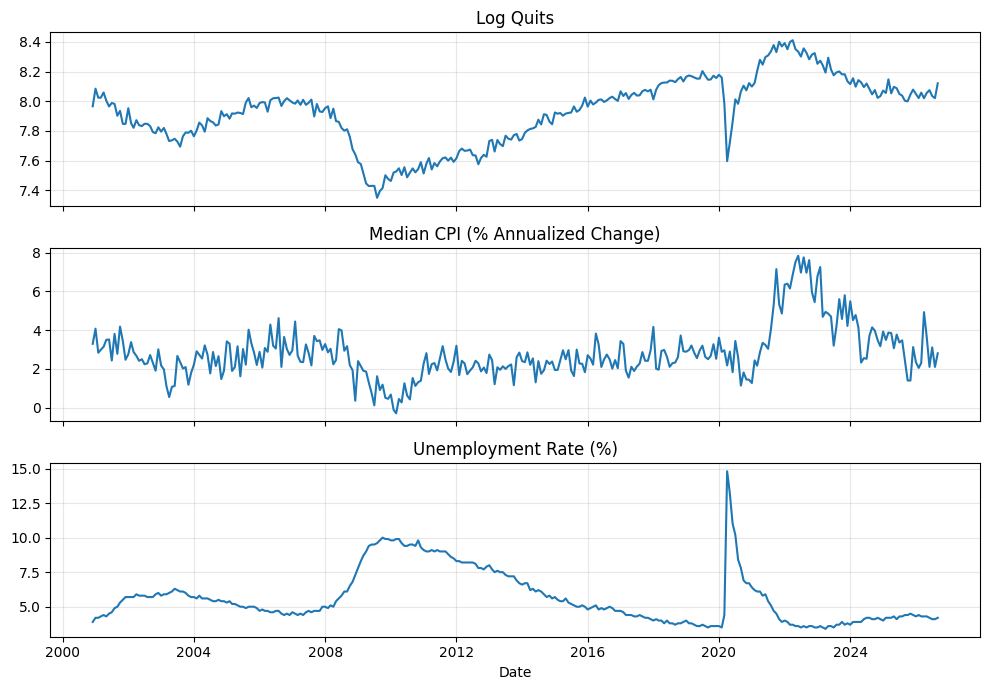

In [54]:
#creating a copy for plotting
Y_plot = Y.copy()

#log-transforming quits
Y_plot["quits"] = np.log(Y_plot["quits"])

#creating three subplots
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

variables = ["quits", "mcpi", "unemp"]

titles = ["Log Quits", "Median CPI (% Annualized Change)", "Unemployment Rate (%)"]

for ax, col, title in zip(axes, variables, titles):
    ax.plot(Y_plot.index, Y_plot[col])
    ax.set_title(title)
    ax.grid(alpha=0.3)

plt.xlabel("Date")
plt.tight_layout()
plt.show()

In [55]:
#running adf with constant-only spec
#function
def adf_summary(series, name, maxlag=12):
    res = adfuller(series.dropna(), regression="c", autolag="AIC", maxlag=maxlag, result_object=False)
    return {
        "series": name,
        "ADF stat": res[0],
        "p-value": res[1],
        "used lag": res[2],
        "nobs": res[3],
        "cv 1%": res[4]["1%"],
        "cv 5%": res[4]["5%"],
        "cv 10%": res[4]["10%"],
    }

#original
adf_levels = pd.DataFrame([adf_summary(Y_plot[c], c) for c in Y_plot.columns])

#first differences
adf_diffs = pd.DataFrame([adf_summary(Y_plot[c].diff(), f"D({c})") for c in Y_plot.columns])

#levels
print("ADF (levels) — constant, without trend")
display(adf_levels.round(4))


ADF (levels) — constant, without trend


,series,ADF stat,p-value,used lag,nobs,cv 1%,cv 5%,cv 10%
0,quits,-1.4374,0.5642,2,307,-3.4518,-2.8710,-2.5718
1,mcpi,-2.5726,0.0988,3,306,-3.4519,-2.8710,-2.5718
2,unemp,-2.9887,0.0360,0,309,-3.4517,-2.8709,-2.5718


So in levels, we get 3 kind of different results. We have negative ADF stats for all 3 variables, but:
*  for log`quits`, the result proves statistically insignificant and we fail to reject the null hypothesis of a unit root
*  for `mcpi`, we are much closer to having something that is significant, but it is not enough to reject the null hypothesis
*  for `unemp`, we reject the null hypothesis and have evidence consistent with stationarity.  

In [56]:
#first differences
print("\nADF (first differences) — constant, without trend")
display(adf_diffs.round(4))


ADF (first differences) — constant, without trend


,series,ADF stat,p-value,used lag,nobs,cv 1%,cv 5%,cv 10%
0,D(quits),-14.5724,0.0,1,307,-3.4518,-2.8710,-2.5718
1,D(mcpi),-15.3506,0.0,2,306,-3.4519,-2.8710,-2.5718
2,D(unemp),-10.3956,0.0,3,305,-3.4520,-2.8711,-2.5718


Here, all three ADF stats are decidedly negative and the p-value is being rounded to 0, meaning that we can reject the null hypothesis that there are unit roots.

## Plotting Results

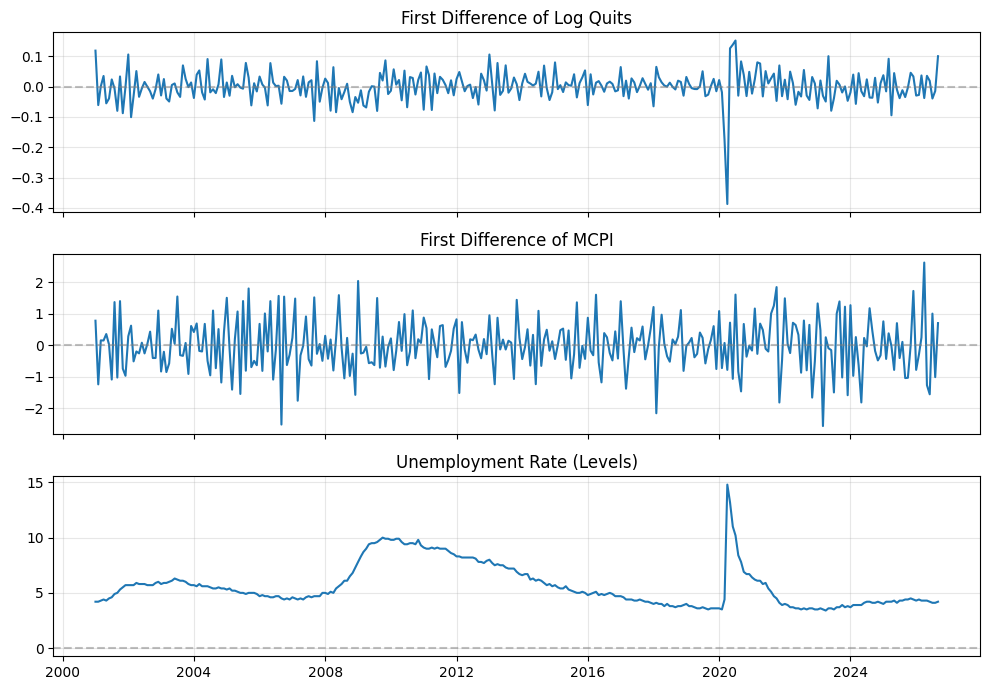

In [57]:
#plotting first differences of log quits and mcpi and unemp in levels to examine mean and variances:

Y_transformed = pd.DataFrame({
    "d_log_quits": Y_plot["quits"].diff(),
    "d_mcpi": Y_plot["mcpi"].diff(),
    "unemp": Y_plot["unemp"]
}).dropna()

#ploting each series
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

titles = ["First Difference of Log Quits", "First Difference of MCPI", "Unemployment Rate (Levels)"]

for ax, col, title in zip(axes, Y_transformed.columns, titles):
    ax.plot(Y_transformed.index, Y_transformed[col])
    ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
    ax.set_title(title)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [58]:
#just curious about what the ADF tests give pre-Covid:

#selecting just observations before 03-2020
Y_pre_covid = Y_plot.loc[Y_plot.index < "2020-03-01"]

#comparing ADF results
adf_pre_covid = pd.DataFrame([
    adf_summary(Y_pre_covid[c], c)
    for c in Y_pre_covid.columns
])

display(adf_pre_covid.round(4))


,series,ADF stat,p-value,used lag,nobs,cv 1%,cv 5%,cv 10%
0,quits,-1.5636,0.5018,6,224,-3.4599,-2.8745,-2.5737
1,mcpi,-3.2175,0.0190,11,219,-3.4606,-2.8748,-2.5739
2,unemp,-1.9533,0.3074,6,224,-3.4599,-2.8745,-2.5737


This is quite interesting! So the `mcpi` ADF result is significant pre-Covid (for the period I'm examining here), but not when looking at the full period 2001-2026. And `unemp` no longer gives a ADF stat that would lead us to reject the null hypothesis of a unit root. So depending on what timeframe we look at, the results can vary quite a bit.

I'm going to run VAR on the full dataset and see what I get in terms of VAR lag order.

In [59]:
#preparing data based on ADF results, differencing
Y_var = pd.DataFrame({"d_log_quits": Y_plot["quits"].diff(), "d_mcpi": Y_plot["mcpi"].diff(), "unemp": Y_plot["unemp"]}).dropna()

#lag selection
var_model = VAR(Y_var)
sel = var_model.select_order(maxlags=13)

print("Lag selection:", sel.selected_orders)

#selecting lag order using BIC
p = sel.selected_orders.get("bic")

if p is None:
    candidates = [v for v in sel.selected_orders.values() if v is not None]
    p = min(candidates) if candidates else 2

print(f"\nEstimating VAR with p = {p}")

#estimating VAR
var_results = var_model.fit(p)

#checking stability
print("Stable?", var_results.is_stable())

#display results
print(var_results.summary())

Lag selection: {'aic': np.int64(3), 'bic': np.int64(2), 'hqic': np.int64(3), 'fpe': np.int64(3)}

Estimating VAR with p = 2
Stable? True
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Fri, 06, Nov, 2026
Time:                     00:23:26
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                   -7.73888
Nobs:                     307.000    HQIC:                  -7.89186
Log likelihood:          -58.7928    FPE:                0.000337554
AIC:                     -7.99381    Det(Omega_mle):     0.000315478
--------------------------------------------------------------------
Results for equation d_log_quits
                    coefficient       std. error           t-stat            prob
---------------------------------------------------------------------------------
const                 -0.026874         0.008598           -3.126           0

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


## Plotting VAR Residuals

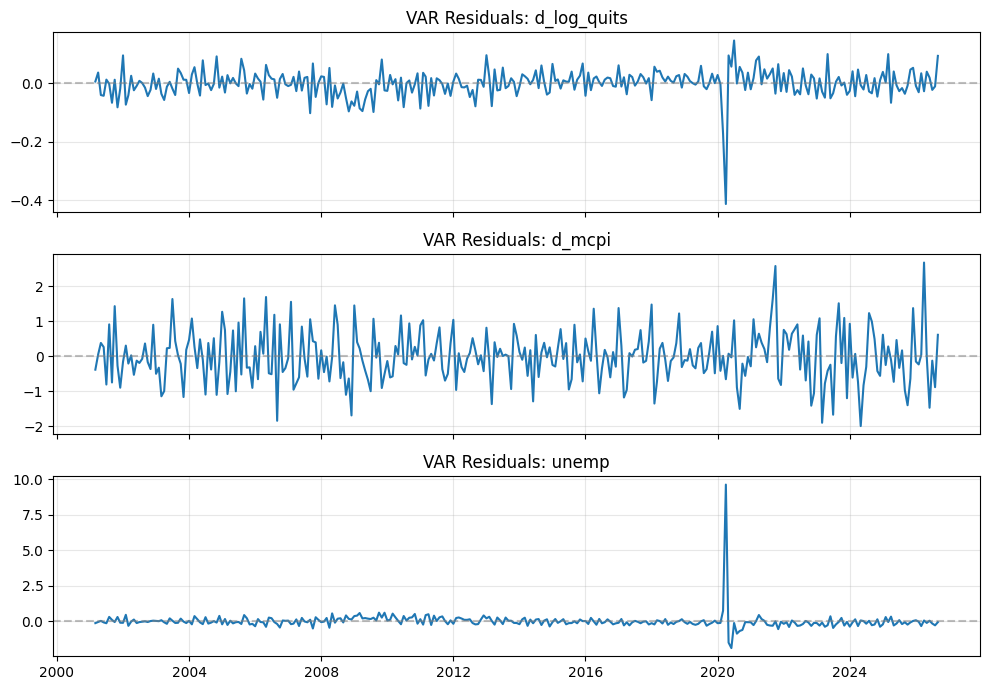

In [60]:
#plotting residuals
#getting fitted values
fitted = var_results.fittedvalues

#aligning actual values with fitted values
actual = Y_var.iloc[p:]

#calculating residuals
resid = actual - fitted

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

for ax, col in zip(axes, resid.columns):
    ax.plot(resid.index, resid[col])
    ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
    ax.set_title(f"VAR Residuals: {col}")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [61]:
#testing for residual autocorrelation through 12 months
whiteness = var_results.test_whiteness(nlags=12)

print(whiteness.summary())

Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 12 is zero. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         141.9          113.1   0.000 90
----------------------------------------


Yikes. We have statistical evidence of autocorrelation here. Going to retry fitting Var(3) as suggested by AIC, HQIC, and FPE.

In [62]:
#fiting VAR(3)
var_results_3 = var_model.fit(3)

#checking stability
print("Stable?", var_results_3.is_stable())

#checking residual autocorrelation
print(var_results_3.test_whiteness(nlags=12).summary())

Stable? True
Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 12 is zero. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         122.5          103.0   0.002 81
----------------------------------------


Oh dear.

Checking now to see if the problem exists pre-Covid:

In [63]:
#selecting observations before 03-2020
Y_pre = Y_var.loc[Y_var.index < "2020-03-01"]

#estimating VAR(2) and VAR(3) on pre-COVID data
var_2_pre = VAR(Y_pre).fit(2)
var_3_pre = VAR(Y_pre).fit(3)

#checking stability
print("Stable VAR(2)?", var_2_pre.is_stable())
print("Stable VAR(3)?", var_3_pre.is_stable())
print()
print(var_2_pre.test_whiteness(nlags=12).summary())
print(var_3_pre.test_whiteness(nlags=12).summary())

Stable VAR(2)? True
Stable VAR(3)? True

Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 12 is zero. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         222.6          113.1   0.000 90
----------------------------------------
Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 12 is zero. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         163.7          103.0   0.000 81
----------------------------------------


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


We still have statistical evidence of autocorrelation even only using data prior to Covid. Trying different lags:

In [64]:
Y_var = Y_var.asfreq("MS")
results = []

for p in [2, 3, 4, 6, 9, 12]:
    model = VAR(Y_var).fit(p)
    test = model.test_whiteness(nlags=18)

    results.append({
        "lags": p,
        "stable": model.is_stable(),
        "AIC": model.aic,
        "BIC": model.bic,
        "whiteness_p": test.pvalue
    })

pd.DataFrame(results).round(4)

,lags,stable,AIC,BIC,whiteness_p
0,2,True,-7.9938,-7.7389,0.0019
1,3,True,-8.0357,-7.6706,0.0086
2,4,True,-8.0032,-7.5275,0.0109
3,6,True,-8.0006,-7.3020,0.0458
4,9,True,-7.9650,-6.9279,0.0388
5,12,True,-7.9242,-6.5437,0.0552


Because only VAR(12) passes the auto-correlation test, there must be something going on. Visualizing autocorrelation:

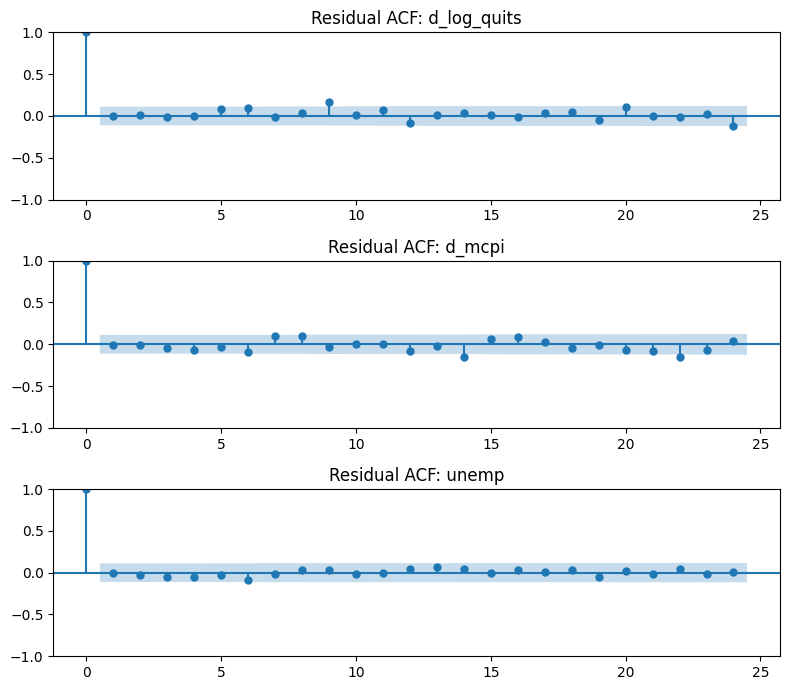

In [65]:
from statsmodels.graphics.tsaplots import plot_acf

resid = var_results_3.resid

fig, axes = plt.subplots(3, 1, figsize=(8, 7))

for ax, col in zip(axes, resid.columns):
    plot_acf(resid[col], lags=24, ax=ax)
    ax.set_title(f"Residual ACF: {col}")

plt.tight_layout()
plt.show()

This actually doesn't look too bad to me. I feel a bit stumped about what is really happening here and why the estimated VARs are failing the Portmanteau test all the way up to lag 12.

## Forecasting

For forecasting, I'm going to go with the VAR(3) model, since that's what AIC, HQIC, and FPE all suggested.

In [66]:
#creating 12 month forecast:

#seting forecast window
last_obs = Y_var.index[-1]
window_start = last_obs - pd.DateOffset(months=24)
target_end = last_obs + pd.DateOffset(months=12)

#calculating forecast horizon
h = (target_end.year - last_obs.year) * 12 + (target_end.month - last_obs.month)

#preparing last p lags
p = var_results_3.k_ar
y0 = var_results_3.endog[-p:]

#forecasting transformed variables
fc_arr = var_results_3.forecast(y=y0, steps=h)

fc_months = pd.date_range(last_obs + pd.offsets.MonthBegin(1), periods=h, freq="MS")

fc = pd.DataFrame(fc_arr, columns=Y_var.columns, index=fc_months)

#converting forecasts back to original units
fc_actual = pd.DataFrame(index=fc_months)

#quits: undoing log difference
fc_actual["quits"] = np.exp(Y_plot["quits"].iloc[-1] + fc["d_log_quits"].cumsum())

#MCPI: undoing first difference
fc_actual["mcpi"] = (Y_plot["mcpi"].iloc[-1] + fc["d_mcpi"].cumsum())

#Unemployment: already in levels
fc_actual["unemp"] = fc["unemp"]

display(fc_actual.round(3))

,quits,mcpi,unemp
2026-10-01,3258.465,2.785,3.843
2026-11-01,3216.300,2.840,3.814
2026-12-01,3229.034,2.550,4.015
2027-01-01,3198.202,2.705,4.104
2027-02-01,3171.047,2.705,4.165
2027-03-01,3155.950,2.670,4.247
2027-04-01,3140.065,2.641,4.338
2027-05-01,3121.529,2.656,4.404
2027-06-01,3105.711,2.646,4.471
2027-07-01,3091.553,2.634,4.538


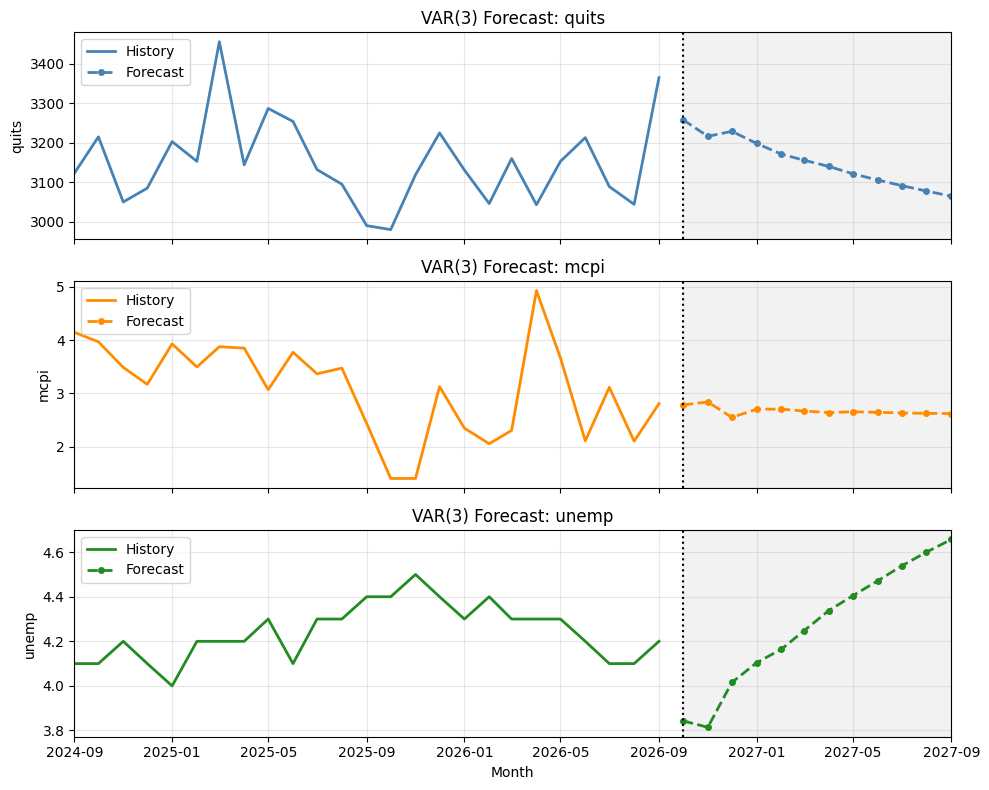

In [67]:
#historical data and forecast window
hist = Y.loc[window_start:last_obs]
fcast = fc_actual.loc[window_start:target_end]

#ploting
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

colors = ["steelblue", "darkorange", "forestgreen"]

for ax, col, color in zip(axes, hist.columns, colors):

    #historical observations
    ax.plot(
        hist.index, hist[col],
        color=color,
        linewidth=2,
        label="History"
    )

    #forecasting
    ax.plot(
        fcast.index, fcast[col],
        color=color,
        linestyle="--",
        marker="o",
        markersize=4,
        linewidth=2,
        label="Forecast"
    )

    # Forecast boundary
    forecast_start = last_obs + pd.offsets.MonthBegin(1)
    ax.axvline(forecast_start, color="black", linestyle=":")

    # Shaded forecast period
    ax.axvspan(forecast_start, target_end, color="gray", alpha=0.1)

    ax.set_title(f"VAR(3) Forecast: {col}")
    ax.set_ylabel(col)
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Month")
axes[-1].set_xlim(window_start, target_end)

plt.tight_layout()
plt.show()

I'm sort of surprised that the quits function is kind of steep, especially compared to MCPI, which is just kind of predicting a relatively unexciting line that looks suspiciously like some kind of mean, but that is more in line with my (limited) experience with forecasts. I guess, when consulting the units, the change is not enormous, but it still demonstrates more variation than we see in the 2-year period prior to the forecast. I have a hard time having a lot of confidence in these forecasts. I am interested to see if, in the next lecture about forecasting, we learn some techniques that could help me deal with the kinds of issues I'm facing here.

Overall, what we can say is that the model is predicing a decline in quits while the unemployment rate rises. That's essentially what I suspected I might see when I chose the variables.

The VAR residual pattern with MCPI in general was more consistent than that of unemployment and quits, which were both subject to effects from the Covid shocks. That could be why the forecast has a flatter slope. The forecast seems to just be converging toward a mean.